<a href="https://colab.research.google.com/github/K-KARTHIKRAJA/Spam-Message-Detector/blob/main/AI_Spam_Message_Detector.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Imports**

In [7]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

RANDOM_STATE = 100
plt.rcParams["figure.dpi"] = 110

**Upload and load the data**

In [8]:
if not os.path.exists("spam.csv"):
    from google.colab import files
    files.upload()

df = pd.read_csv("spam.csv", encoding="latin-1")
print("Raw shape:", df.shape)
df.head()

Raw shape: (5572, 5)


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


**Clean the data**

In [9]:
df = df[["v1", "v2"]].copy()
df.columns = ["label", "message"]

before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {before - len(df)} duplicates -> {len(df)} remain")

df["target"] = df["label"].map({"ham": 0, "spam": 1})
print("Missing values:", df.isna().sum().sum())
df["label"].value_counts()

Removed 403 duplicates -> 5169 remain
Missing values: 0


,count
label,
ham,4516
spam,653


**EDA, class distribution**

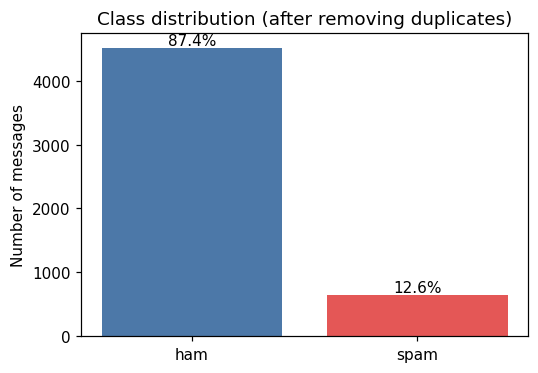

In [17]:
counts = df["label"].value_counts()
pct = (counts / counts.sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(counts.index, counts.values, color=["#4C78A8", "#E45756"])
for b, p in zip(bars, pct):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{p}%", ha="center", va="bottom")
ax.set_title("Class distribution (after removing duplicates)")
ax.set_ylabel("Number of messages")
plt.tight_layout()
plt.savefig("eda_class_distribution.png")
plt.show()

**EDA, message length**

       length  word_count
label                    
ham      70.5        14.1
spam    137.9        23.7


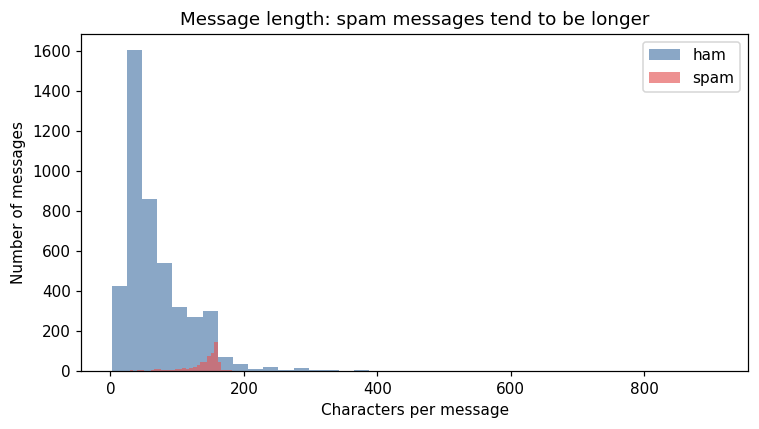

In [18]:
df["length"] = df["message"].str.len()
df["word_count"] = df["message"].str.split().str.len()
print(df.groupby("label")[["length", "word_count"]].mean().round(1))

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df.loc[df.label == "ham", "length"], bins=40, alpha=0.65, label="ham", color="#4C78A8")
ax.hist(df.loc[df.label == "spam", "length"], bins=40, alpha=0.65, label="spam", color="#E45756")
ax.set_title("Message length: spam messages tend to be longer")
ax.set_xlabel("Characters per message")
ax.set_ylabel("Number of messages")
ax.legend()
plt.tight_layout()
plt.savefig("eda_message_length.png")
plt.show()

**EDA, extra signals**

In [19]:
df["has_digits"] = df["message"].str.contains(r"\d{5,}").astype(int)
df["has_url"] = df["message"].str.contains(r"http|www\.", case=False).astype(int)
df["has_money"] = df["message"].str.contains(r"[£$€]|\bfree\b|\bwin\b|\bprize\b", case=False).astype(int)

(df.groupby("label")[["has_digits", "has_url", "has_money"]].mean() * 100).round(1)

,has_digits,has_url,has_money
label,,,
ham,0.1,0.0,1.7
spam,76.6,13.9,54.2


**Baseline (why accuracy misleads)**

In [20]:
baseline_acc = (df["target"] == 0).mean()
print(f"Always-predict-ham accuracy: {baseline_acc:.1%}")
print("Looks great, but it catches 0% of spam. So we focus on precision and recall.")

Always-predict-ham accuracy: 87.4%
Looks great, but it catches 0% of spam. So we focus on precision and recall.


**Train/test split**

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    df["message"], df["target"],
    test_size=0.2, stratify=df["target"], random_state=RANDOM_STATE
)
print("Train:", len(X_train), "| Test:", len(X_test))
print("Spam share  train: {:.1%}  test: {:.1%}".format(y_train.mean(), y_test.mean()))

Train: 4135 | Test: 1034
Spam share  train: 12.6%  test: 12.7%


**Train both models and compare**

In [23]:
def make_tfidf():
    return TfidfVectorizer(lowercase=True, stop_words="english", ngram_range=(1, 2), min_df=2)

models = {
    "Naive Bayes": Pipeline([("tfidf", make_tfidf()), ("clf", MultinomialNB(alpha=0.1))]),
    "Logistic Regression": Pipeline([("tfidf", make_tfidf()),
                                     ("clf", LogisticRegression(max_iter=1000,
                                                                class_weight="balanced",
                                                                random_state=RANDOM_STATE))]),
}

results, preds = [], {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    preds[name] = y_pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (spam)": precision_score(y_test, y_pred),
        "Recall (spam)": recall_score(y_test, y_pred),
        "F1 (spam)": f1_score(y_test, y_pred),
    })

results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df

,Accuracy,Precision (spam),Recall (spam),F1 (spam)
Model,,,,
Naive Bayes,0.9903,1.0000,0.9237,0.9603
Logistic Regression,0.9836,0.9453,0.9237,0.9344


**Classification reports**

In [24]:
for name, y_pred in preds.items():
    print(f"=== {name} ===")
    print(classification_report(y_test, y_pred, target_names=["ham", "spam"], digits=3))

=== Naive Bayes ===
              precision    recall  f1-score   support

         ham      0.989     1.000     0.994       903
        spam      1.000     0.924     0.960       131

    accuracy                          0.990      1034
   macro avg      0.995     0.962     0.977      1034
weighted avg      0.990     0.990     0.990      1034

=== Logistic Regression ===
              precision    recall  f1-score   support

         ham      0.989     0.992     0.991       903
        spam      0.945     0.924     0.934       131

    accuracy                          0.984      1034
   macro avg      0.967     0.958     0.962      1034
weighted avg      0.983     0.984     0.983      1034



**Confusion matrices**

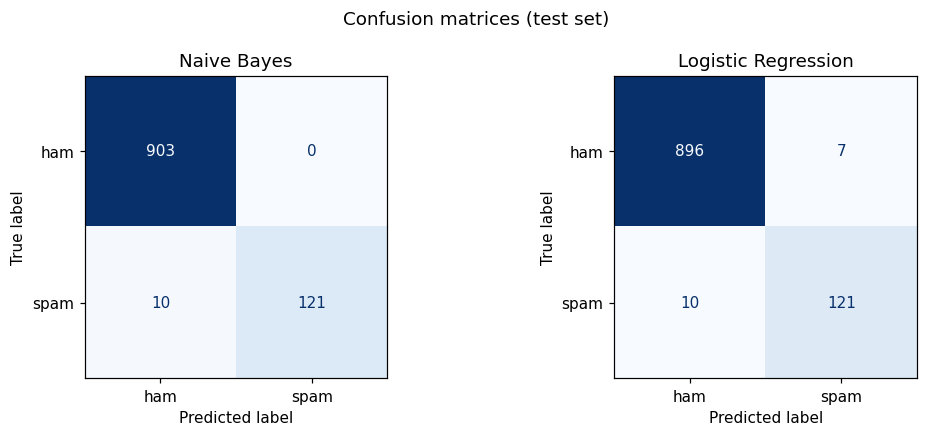

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, y_pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=["ham", "spam"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.suptitle("Confusion matrices (test set)")
plt.tight_layout()
plt.savefig("confusion_matrices.png")
plt.show()

**Model comparison chart**

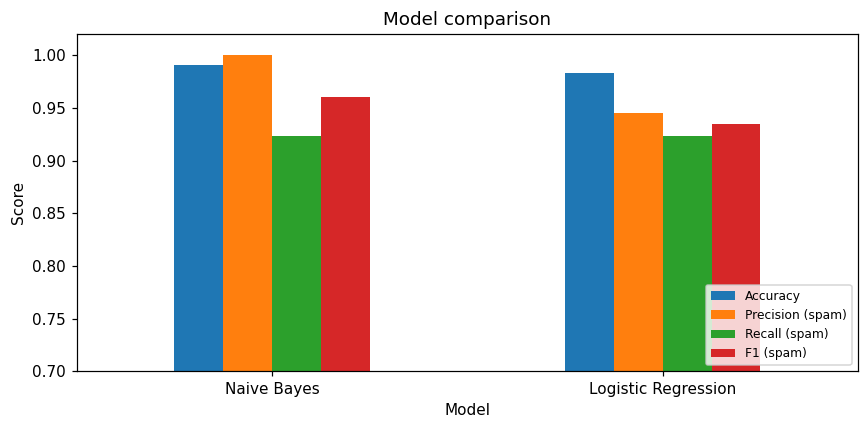

In [26]:
ax = results_df.plot(kind="bar", figsize=(8, 4), rot=0, ylim=(0.7, 1.02))
ax.set_title("Model comparison")
ax.set_ylabel("Score")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("model_comparison.png")
plt.show()

**Pick the best model**

In [27]:
best_name = results_df["F1 (spam)"].idxmax()
best_model = models[best_name]
print("Selected model:", best_name)
print(results_df.loc[best_name])

Selected model: Naive Bayes
Accuracy            0.9903
Precision (spam)    1.0000
Recall (spam)       0.9237
F1 (spam)           0.9603
Name: Naive Bayes, dtype: float64


**Error analysis**

In [28]:
y_pred_best = preds[best_name]
errors = pd.DataFrame({"message": X_test.values, "actual": y_test.values, "predicted": y_pred_best})

false_pos = errors[(errors.actual == 0) & (errors.predicted == 1)]
false_neg = errors[(errors.actual == 1) & (errors.predicted == 0)]

print(f"False positives (real messages blocked): {len(false_pos)}")
print(f"False negatives (spam missed): {len(false_neg)}\n")

pd.set_option("display.max_colwidth", 140)
print("--- Spam the model missed ---")
display(false_neg.head(5)[["message"]])
print("--- Real messages wrongly flagged ---")
display(false_pos.head(5)[["message"]])

False positives (real messages blocked): 0
False negatives (spam missed): 10

--- Spam the model missed ---


,message
18,Money i have won wining number 946 wot do i do next
77,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about we go slo n hard! Tx...
194,This message is brought to you by GMW Ltd. and is not connected to the
322,"Will u meet ur dream partner soon? Is ur career off 2 a flyng start? 2 find out free, txt HORO followed by ur star sign, e. g. HORO ARIES"
421,"In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Day, C-Red Day. (Send ..."


--- Real messages wrongly flagged ---


,message


**Top spam and ham words**

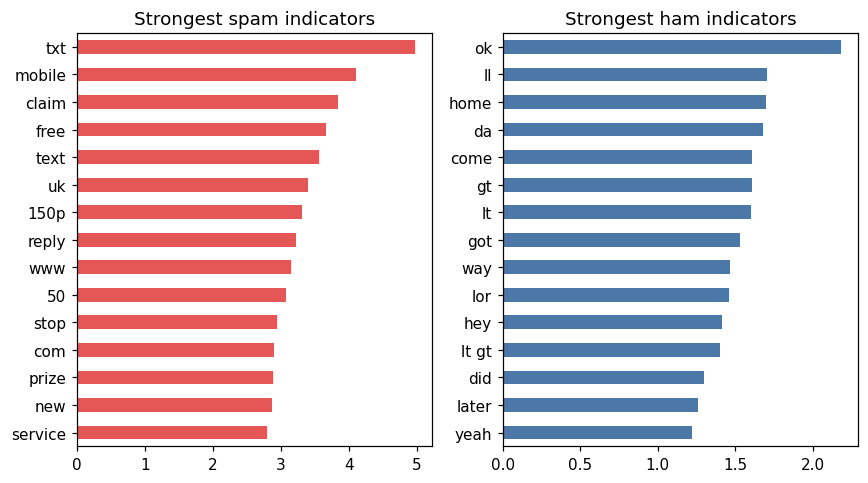

In [30]:
lr = models["Logistic Regression"]
vec = lr.named_steps["tfidf"]
coefs = lr.named_steps["clf"].coef_[0]
terms = np.array(vec.get_feature_names_out())

top_spam = pd.Series(coefs, index=terms).nlargest(15)
top_ham = pd.Series(coefs, index=terms).nsmallest(15)

fig, axes = plt.subplots(1, 2, figsize=(8, 4.5))
top_spam[::-1].plot(kind="barh", ax=axes[0], color="#E45756")
axes[0].set_title("Strongest spam indicators")
top_ham[::-1].abs().plot(kind="barh", ax=axes[1], color="#4C78A8")
axes[1].set_title("Strongest ham indicators")
plt.tight_layout()
plt.savefig("top_words.png")
plt.show()

**The predict() function**

In [31]:
def predict(message, model=best_model, threshold=0.5):
    """Classify a message as SPAM or HAM and show the spam probability."""
    prob = model.predict_proba([message])[0][1]
    label = "SPAM" if prob >= threshold else "HAM"
    print(f"{label:<5} (spam probability: {prob:.1%})  |  {message[:90]}")
    return label, prob

samples = [
    "Congratulations! You've won a FREE iPhone. Click http://claim-prize.example to collect now!",
    "URGENT: Your account has been suspended. Reply with your OTP to verify.",
    "Hey, are we still meeting for lunch at 1pm tomorrow?",
    "Can you send me the notes from today's lecture?",
    "WINNER!! You have been selected for a 1000 cash prize. Call 09061701461 now",
    "Your bank statement is ready. Log in to view it.",
]
for s in samples:
    predict(s)

SPAM  (spam probability: 100.0%)  |  Congratulations! You've won a FREE iPhone. Click http://claim-prize.example to collect now
SPAM  (spam probability: 92.4%)  |  URGENT: Your account has been suspended. Reply with your OTP to verify.
HAM   (spam probability: 0.1%)  |  Hey, are we still meeting for lunch at 1pm tomorrow?
HAM   (spam probability: 2.1%)  |  Can you send me the notes from today's lecture?
SPAM  (spam probability: 100.0%)  |  WINNER!! You have been selected for a 1000 cash prize. Call 09061701461 now
HAM   (spam probability: 30.2%)  |  Your bank statement is ready. Log in to view it.


**Testing Spam or Ham**

In [34]:
predict("gpay to 100 rupees 1234567890 this number to claim the prize")

SPAM  (spam probability: 99.5%)  |  gpay to 100 rupees 1234567890 this number to claim the prize


('SPAM', np.float64(0.9952852217720971))

In [36]:
predict("Hii, I'm Karthikraja.")

HAM   (spam probability: 12.6%)  |  Hii, I'm Karthikraja.


('HAM', np.float64(0.12623941958887555))